# EduVidQA official annotation EDA

Pinned source: [official author repository](https://github.com/sourjyadip/eduvidqa-emnlp25) at commit `aab6cc03e43182cc916f14ed2aca495f57a1ed96`; paper: [EMNLP 2025](https://aclanthology.org/2025.emnlp-main.1760/). This notebook downloads the three released CSV files from that commit if absent, checks their SHA-256, and analyzes all source annotation rows. It does **not** download 296 YouTube videos or transcripts automatically: access, rights and revisions must be recorded per video. No model runs here.

The three CSVs contain released QA references. This analysis uses test rows for structural counts and question/ID overlap, but does not print test answers or assess their semantics. Test is not claimed to be untouched. There are no independent evidence-span/relevance labels for retrieval Recall@k.

In [8]:
from pathlib import Path
import csv, hashlib, os, re, urllib.request
from collections import Counter
from urllib.parse import urlparse, parse_qs
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

def find_root():
    override = os.environ.get("BENCHMARK_ROOT")
    candidates = [Path(override)] if override else []
    for base in [Path.cwd(), *Path.cwd().parents]:
        candidates += [base, base / "benchmark"]
    for base in candidates:
        if (base / "docs/BENCHMARK.md").is_file() and (base / "experiments/notebooks").is_dir():
            return base.resolve()
    raise FileNotFoundError("Set BENCHMARK_ROOT to the benchmark repository.")

ROOT = find_root()
DATA = Path(os.environ.get("EDUVIDQA_DATA_ROOT", ROOT / "research-data/eduvidqa-official/data"))
REV = "aab6cc03e43182cc916f14ed2aca495f57a1ed96"
FILES = {
    "synthetic_train": ("synthetic_train.csv", "3c6471d5c01b92a8092a8dcff367f701fbdd80b34f8b02f5c55e0e8ba0a971f5"),
    "synthetic_test": ("synthetic_test.csv", "0c44b89987ea1f112e5a46843036320132cebd111b37c1203591d31110c2bbaf"),
    "real_world_test": ("real_world_test.csv", "2b8553dd454cb7038c914809a9c4e3908161955b243de97dc490493c8c092055"),
}
BASE = f"https://raw.githubusercontent.com/sourjyadip/eduvidqa-emnlp25/{REV}/data/"
DATA.mkdir(parents=True, exist_ok=True)
for split, (name, expected) in FILES.items():
    path = DATA / name
    if not path.exists():
        with urllib.request.urlopen(BASE + name, timeout=60) as response:
            blob = response.read()
        assert hashlib.sha256(blob).hexdigest() == expected, f"{name}: source checksum mismatch"
        path.write_bytes(blob)
    actual = hashlib.sha256(path.read_bytes()).hexdigest()
    assert actual == expected, f"{name}: local checksum mismatch"
    print(split, name, path.stat().st_size, actual[:16])
print("Source: author release pinned by Git commit and per-file SHA-256.")

synthetic_train synthetic_train.csv 4463240 3c6471d5c01b92a8
synthetic_test synthetic_test.csv 1212030 0c44b89987ea1f11
real_world_test real_world_test.csv 128601 2b8553dd454cb703
Source: author release pinned by Git commit and per-file SHA-256.


In [8]:
COLUMN_MAP = {
    "synthetic_train": ("vid_id", "vid_url", "final_question", "final_answer"),
    "synthetic_test": ("vid_id", "vid_url", "question", "answer"),
    "real_world_test": ("id", "url", "question", "answer"),
}
records = []
for split, (name, _) in FILES.items():
    with (DATA / name).open(encoding="utf-8-sig", newline="") as stream:
        reader = csv.DictReader(stream)
        video_col, url_col, question_col, answer_col = COLUMN_MAP[split]
        assert {video_col, url_col, question_col, answer_col, "timestamp"} <= set(reader.fieldnames or [])
        for index, row in enumerate(reader, 1):
            records.append({
                "split": split, "source_row": index, "video_id": (row[video_col] or "").strip(),
                "video_url": (row[url_col] or "").strip(),
                "timestamp": (row["timestamp"] or "").strip(),
                "question": (row[question_col] or "").strip(),
                "answer": (row[answer_col] or "").strip(),
            })
df = pd.DataFrame(records)
assert df.groupby("split").size().to_dict() == {
    "synthetic_train": 3909, "synthetic_test": 1056, "real_world_test": 269}
assert len(df) == 5234
print("Rows read:", len(df), "| distinct video IDs:", df.video_id.nunique())
display(df.groupby("split").agg(source_rows=("source_row","count"), videos=("video_id","nunique"),
                                blank_id=("video_id",lambda s: int(s.eq("").sum())),
                                blank_url=("video_url",lambda s: int(s.eq("").sum())),
                                blank_question=("question",lambda s: int(s.eq("").sum())),
                                blank_answer=("answer",lambda s: int(s.eq("").sum()))))
print("Unit ID = (source split, physical CSV row); no test-answer content is displayed.")

Rows read: 5234 | distinct video IDs: 296
Unit ID = (source split, physical CSV row); no test-answer content is displayed.


,source_rows,videos,blank_id,blank_url,blank_question,blank_answer
split,,,,,,
real_world_test,269,99,0,0,0,0
synthetic_test,1056,40,0,0,0,0
synthetic_train,3909,157,0,0,0,0


Interpretation: synthetic train dominates row count; the real-world test has fewer rows but more videos than synthetic test.


,qa_rows,videos,qa_per_video
split,,,
real_world_test,269,99,2.7
synthetic_test,1056,40,26.4
synthetic_train,3909,157,24.9


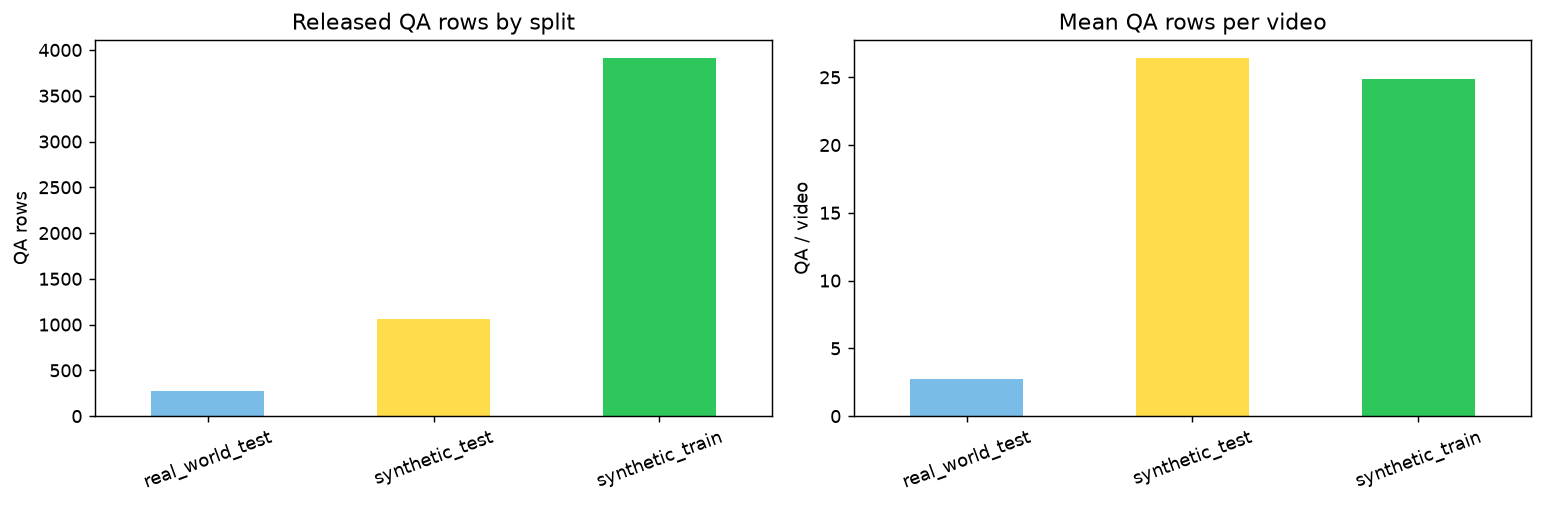

In [8]:
summary = df.groupby("split").agg(qa_rows=("source_row","count"), videos=("video_id","nunique"))
summary["qa_per_video"] = (summary.qa_rows / summary.videos).round(1)
display(summary)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
summary.qa_rows.plot.bar(ax=axes[0], color=["#7abce8","#ffdc4a","#2dc75c"])
axes[0].set(title="Released QA rows by split", ylabel="QA rows", xlabel="")
summary.qa_per_video.plot.bar(ax=axes[1], color=["#7abce8","#ffdc4a","#2dc75c"])
axes[1].set(title="Mean QA rows per video", ylabel="QA / video", xlabel="")
for ax in axes: ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()
print("Interpretation: synthetic train dominates row count; the real-world test has fewer rows but more videos than synthetic test.")

## Timestamp format and availability

Two-component timestamps are interpreted as minutes:seconds only when seconds are in 0–59. Three-component strings are **not** silently interpreted: source data contain both long lecture values and forms such as `25:59:00`; the intended timebase must be checked against media/transcripts before using them for retrieval windows.

Training examples with unresolved three-part time (first 8):
No media durations are available to validate time range or transcript alignment.


timestamp_format,blank,m:s,m:ss,three_part_unresolved
split,,,,
synthetic_train,0,419,3071,419
synthetic_test,1038,0,18,0
real_world_test,0,0,232,37


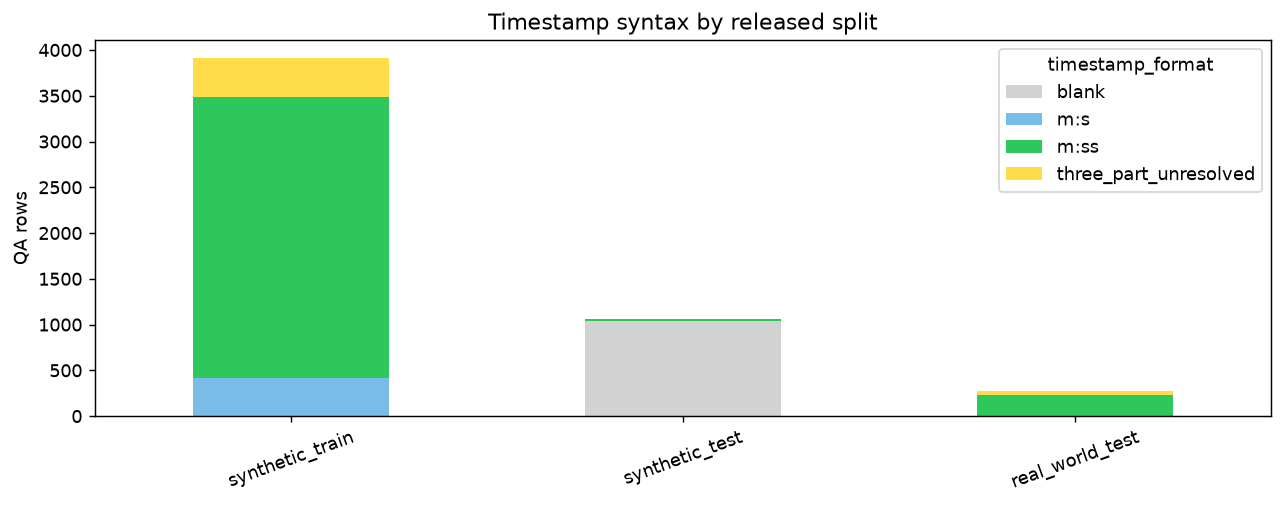

,source_row,video_id,timestamp
4,5,8jqKOqwOwA4,25:59:00
9,10,8jqKOqwOwA4,30:30:00
48,49,_Xv3isxvQak,26:32:00
49,50,_Xv3isxvQak,24:59:00
72,73,Fycxqql9qcc,24:26:00
73,74,Fycxqql9qcc,26:18:00
74,75,Fycxqql9qcc,25:46:00
93,94,0Lg5E1nlSOs,27:16:00


In [8]:
def classify_time(value):
    if not value: return "blank"
    parts = value.split(":")
    if len(parts) == 2 and all(x.isdigit() for x in parts) and 0 <= int(parts[1]) < 60:
        return "m:ss" if len(parts[1]) == 2 else "m:s"
    if len(parts) == 3 and all(x.isdigit() for x in parts):
        return "three_part_unresolved"
    return "invalid"
df["timestamp_format"] = df.timestamp.map(classify_time)
formats = pd.crosstab(df.split, df.timestamp_format).reindex(FILES, fill_value=0)
display(formats)
formats.plot.bar(stacked=True, figsize=(10, 4),
                 color={"blank":"#d2d2d2","m:ss":"#2dc75c","m:s":"#7abce8",
                        "three_part_unresolved":"#ffdc4a","invalid":"#ed6a5a"})
plt.title("Timestamp syntax by released split"); plt.ylabel("QA rows"); plt.xlabel("")
plt.xticks(rotation=20); plt.tight_layout(); plt.show()
print("Training examples with unresolved three-part time (first 8):")
display(df.loc[(df.split=="synthetic_train") & (df.timestamp_format=="three_part_unresolved"),
               ["source_row","video_id","timestamp"]].head(8))
print("No media durations are available to validate time range or transcript alignment.")

## Video linkage, duplicates and concentration

This is a structural check. Shared exact question text is not proof of the same answer or video content. No answer text from test is printed.

Interpretation: no exact cross-split video ID overlap; course/topic similarity still needs source metadata or transcript review.


,rows,url_id_mismatch,duplicate_questions_within_split,unique_video_ids
split,,,,
real_world_test,269,0,0,99
synthetic_test,1056,0,0,40
synthetic_train,3909,0,0,157


,left,right,shared_video_ids,shared_exact_questions
0,synthetic_train,synthetic_test,0,0
1,synthetic_train,real_world_test,0,0
2,synthetic_test,real_world_test,0,0


,count,mean,std,min,25%,50%,75%,95%,max
split,,,,,,,,,
real_world_test,99.0,2.7,2.1,1.0,1.0,2.0,3.0,7.1,11.0
synthetic_test,40.0,26.4,15.7,5.0,16.0,22.0,40.2,57.0,69.0
synthetic_train,157.0,24.9,13.3,3.0,15.0,22.0,33.0,52.0,72.0


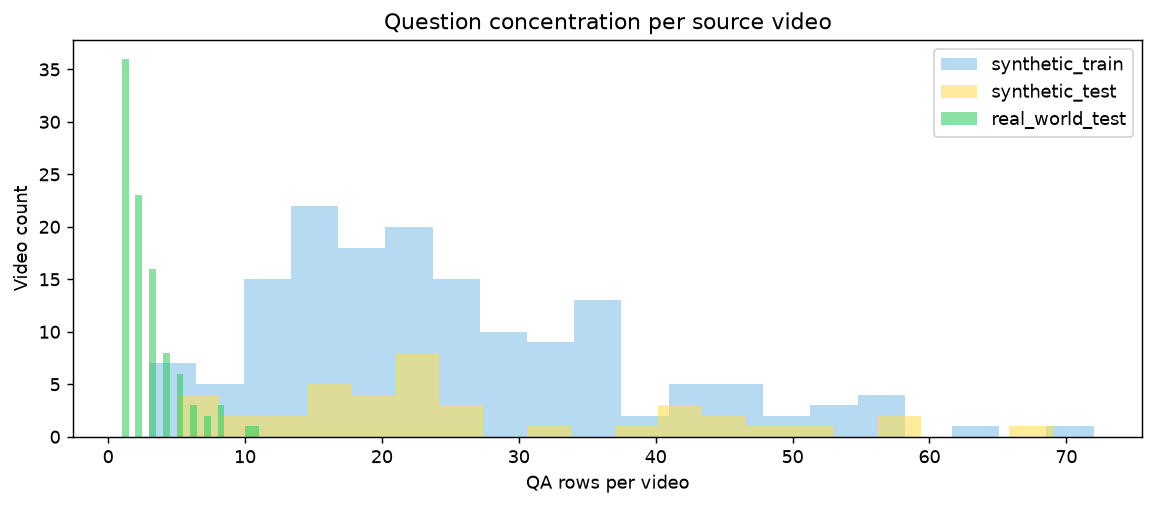

In [8]:
df["url_id"] = df.video_url.map(lambda u: parse_qs(urlparse(u).query).get("v", [""])[0])
df["url_id_matches"] = df.url_id.eq(df.video_id)
df["question_norm"] = df.question.str.casefold().str.replace(r"\s+"," ",regex=True).str.strip()
checks = pd.DataFrame([
    {"split": name, "rows": len(group), "url_id_mismatch": int((~group.url_id_matches).sum()),
     "duplicate_questions_within_split": int(group.question_norm.duplicated().sum()),
     "unique_video_ids": group.video_id.nunique()}
    for name, group in df.groupby("split")
]).set_index("split")
display(checks)
pairs=[]
for a,b in [("synthetic_train","synthetic_test"),("synthetic_train","real_world_test"),("synthetic_test","real_world_test")]:
    left,right = df[df.split==a],df[df.split==b]
    pairs.append({"left":a,"right":b,
                  "shared_video_ids":len(set(left.video_id)&set(right.video_id)),
                  "shared_exact_questions":len(set(left.question_norm)&set(right.question_norm))})
display(pd.DataFrame(pairs))
assert df.url_id_matches.all()
assert all(p["shared_video_ids"]==0 for p in pairs)
video_counts = df.groupby(["split","video_id"]).size().rename("qa_count").reset_index()
display(video_counts.groupby("split").qa_count.describe(percentiles=[.25,.5,.75,.95]).round(1))
fig, ax = plt.subplots(figsize=(9,4))
for name, color in [("synthetic_train","#7abce8"),("synthetic_test","#ffdc4a"),("real_world_test","#2dc75c")]:
    ax.hist(video_counts.loc[video_counts.split==name,"qa_count"], bins=20, alpha=.55, label=name, color=color)
ax.set(title="Question concentration per source video",xlabel="QA rows per video",ylabel="Video count")
ax.legend(); plt.tight_layout(); plt.show()
print("Interpretation: no exact cross-split video ID overlap; course/topic similarity still needs source metadata or transcript review.")

Reference-length plots use training rows only; test answer content remains undisplayed.


,question_words,answer_words
count,3909.0,3909.0
mean,37.1,122.7
std,7.8,31.5
min,13.0,12.0
25%,32.0,101.0
50%,37.0,120.0
75%,42.0,141.0
95%,51.0,179.0
max,78.0,333.0


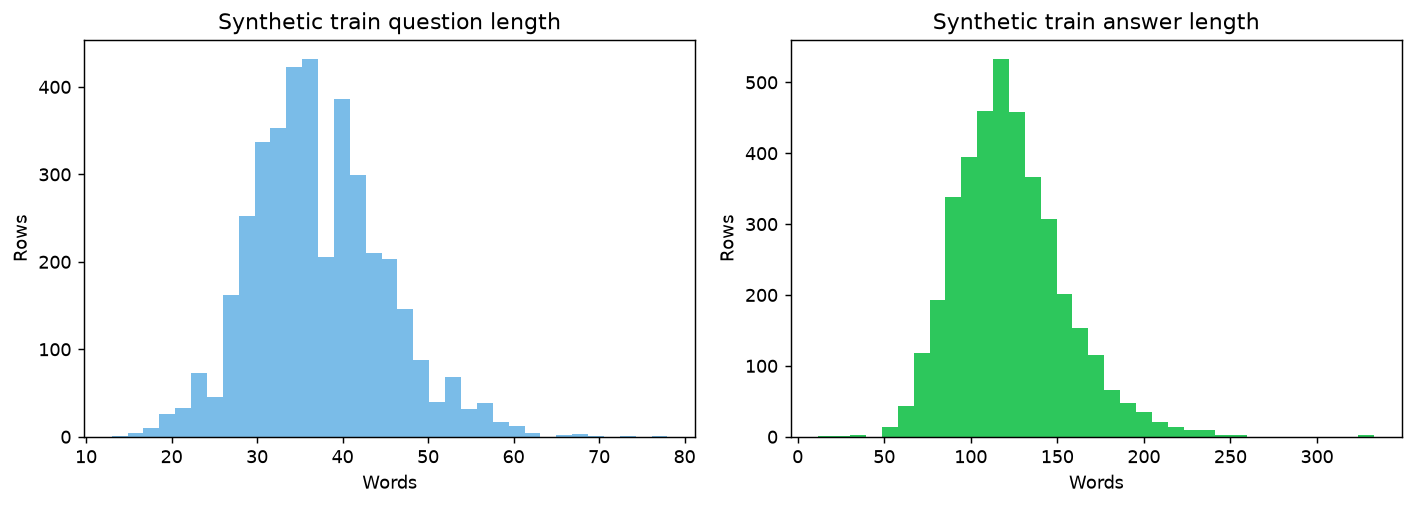

In [8]:
train = df[df.split=="synthetic_train"].copy()
train["question_words"] = train.question.str.split().str.len()
train["answer_words"] = train.answer.str.split().str.len()
display(train[["question_words","answer_words"]].describe(percentiles=[.25,.5,.75,.95]).round(1))
fig, axes = plt.subplots(1,2,figsize=(11,4))
axes[0].hist(train.question_words,bins=35,color="#7abce8")
axes[0].set(title="Synthetic train question length",xlabel="Words",ylabel="Rows")
axes[1].hist(train.answer_words,bins=35,color="#2dc75c")
axes[1].set(title="Synthetic train answer length",xlabel="Words",ylabel="Rows")
plt.tight_layout(); plt.show()
print("Reference-length plots use training rows only; test answer content remains undisplayed.")

In [8]:
MEDIA = Path(os.environ.get("EDUVIDQA_MEDIA_ROOT", ROOT/"experiments/datasets/eduvidqa/media"))
TRANSCRIPTS = Path(os.environ.get("EDUVIDQA_TRANSCRIPT_ROOT", ROOT/"experiments/datasets/eduvidqa/transcripts"))
def files_by_video(root):
    if not root.is_dir(): return set()
    return {p.stem[:11] for p in root.rglob("*") if p.is_file()}
media_ids, transcript_ids = files_by_video(MEDIA), files_by_video(TRANSCRIPTS)
all_ids = set(df.video_id)
print("Local source-video files matched by 11-char ID:",len(all_ids & media_ids),"/",len(all_ids))
print("Local transcript files matched by 11-char ID:",len(all_ids & transcript_ids),"/",len(all_ids))
print("These path checks do not decode media, verify rights, or prove timestamp alignment.")
print("HOLD" if not all_ids <= media_ids or not all_ids <= transcript_ids else
      "File presence only; decode and alignment audit still required.")

Local source-video files matched by 11-char ID: 0 / 296
Local transcript files matched by 11-char ID: 0 / 296
These path checks do not decode media, verify rights, or prove timestamp alignment.
HOLD


## Decision

**HOLD for RQ3 retrieval and video-grounded QA.** All 5,234 released CSV rows have structurally present questions, answers, URLs and IDs; the 296 video IDs do not cross the three splits. However, 1,038 synthetic-test timestamps are blank, 456 timestamps across train/real-test have unresolved three-part syntax, source media/transcript bytes are not part of this CSV release, and no independent evidence-span or relevance GT exists. A timestamp-centered window is an input heuristic, not retrieval ground truth.

The pinned release has 5,234 rows versus 5,252 in the paper; do not silently use the paper denominator. A later answer-only QA study would still need a declared accessible media/transcript cohort and a frozen scoring protocol. No benchmark result or winner follows from this EDA.

## Qualification follow-up — 2026-10-10

Earlier executed outputs are retained as historical evidence. This additive review supersedes their current availability/qualification statements where explicitly recorded in the receipt. KEEP and REPAIR are scoped record-quality decisions, not approval of a benchmark cohort.

In [9]:
from pathlib import Path
import json, hashlib
import pandas as pd
from IPython.display import display, Markdown, Image
saved = json.loads('{"dataset": "eduvidqa", "observed_at_utc": "2026-10-10T08:58:03.066279+00:00", "counts": {"selected": 5234, "observed": 5234, "label_valid": 5234, "media_valid": 0, "evaluated": 0, "failed": 0, "unit": "QA CSV row", "label_valid_definition": "structural annotation only; not independent task GT", "media_valid_definition": "original source videos verified for target endpoint", "failed_definition": "record read/parse failures; HOLD is not a processing failure"}, "artifacts": [{"path": "experiments\\\\outputs\\\\dataset_qualification_261010\\\\eduvidqa-id-ledger.csv", "sha256": "b139365e65cd2e87d2e229f953aca9ab9d2550289f59435a2406f6005e0c9044", "rows": 5234}, {"path": "experiments\\\\outputs\\\\dataset_qualification_261010\\\\eduvidqa-source-group-ledger.csv", "sha256": "6dec070a47062ef16958af54482f39ea4a928c5b56c51216455bf468a0469d8a", "rows": 296}, {"path": "experiments\\\\outputs\\\\dataset_qualification_261010\\\\eduvidqa-sampled-three-part-timebase-review.csv", "sha256": "851b97b6f3eb90f0f69b398754ab44d0b923d620a84114fdbd4ef7d8126e59f8", "rows": 6}, {"path": "experiments\\\\outputs\\\\dataset_qualification_261010\\\\eduvidqa-sample-transcript-probe.json", "sha256": "bcabe9632a67312e9a122fce6bdf0ede0eb324e6339b9c11027c5920e666a4f5"}], "model_inference_run": false, "unseen_reference_claim": false, "sources": [{"path": "research-data\\\\eduvidqa-official\\\\data\\\\synthetic_train.csv", "sha256": "3c6471d5c01b92a8092a8dcff367f701fbdd80b34f8b02f5c55e0e8ba0a971f5"}, {"path": "research-data\\\\eduvidqa-official\\\\data\\\\synthetic_test.csv", "sha256": "0c44b89987ea1f112e5a46843036320132cebd111b37c1203591d31110c2bbaf"}, {"path": "research-data\\\\eduvidqa-official\\\\data\\\\real_world_test.csv", "sha256": "2b8553dd454cb7038c914809a9c4e3908161955b243de97dc490493c8c092055"}], "source_videos": 296, "frozen": false, "three_part_timestamps": 456, "blank_synthetic_test_timestamps": 1038, "cross_split_video_groups": 0, "endpoint": "released-answer agreement diagnostic only after source-context qualification; retrieval relevance HOLD", "blocker": "Official release has no independent evidence spans; media/transcripts and timestamp semantics unverified.", "source_probes": [{"dataset": "eduvidqa", "label": "pinned-readme", "url": "https://raw.githubusercontent.com/sourjyadip/eduvidqa-emnlp25/aab6cc03e43182cc916f14ed2aca495f57a1ed96/README.md", "observed_at_utc": "2026-10-10T08:59:13.883344+00:00", "status": 200, "final_url": "https://raw.githubusercontent.com/sourjyadip/eduvidqa-emnlp25/aab6cc03e43182cc916f14ed2aca495f57a1ed96/README.md", "sha256": "f1c876697540e34da0ce555b271ea0e1043971a163ddf6d1e47910743780ace2", "bytes": 5564, "response_path": "experiments\\\\outputs\\\\dataset_qualification_261010\\\\eduvidqa-pinned-readme.txt"}, {"dataset": "eduvidqa", "id": "-Lw8isQCi4g", "url": "https://youtube.com/watch?v=-Lw8isQCi4g", "observed_at_utc": "2026-10-10T08:59:14.419347+00:00", "scope": "one deterministic source video; metadata extraction only; no media decoded", "exit_code": 0, "stderr": "", "response_path": "experiments\\\\outputs\\\\dataset_qualification_261010\\\\eduvidqa-media-probe--Lw8isQCi4g.txt", "sha256": "95f2f5b9abcc01170320eb02eacd5d748afafd57d1a7175864ae4c026fea9ef1", "duration": 1636, "title": "Lecture 4 : Recurrence of Merge Sort", "license": null, "uploader": "Introduction to Algorithms and Analysis", "media_restored": false, "decision": "HOLD_alignment_and_rights_review"}], "media_probe_limit": "Bounded deterministic source probes only; no full availability survey or original media decode.", "bounded_media_samples": [{"dataset": "eduvidqa", "id": "-Lw8isQCi4g", "url": "https://youtube.com/watch?v=-Lw8isQCi4g", "section": "0-20s", "max_bytes": 30000000, "observed_at_utc": "2026-10-10T09:00:47.722408+00:00", "decision": "HOLD_sample_download_failed", "exit_code": 1, "log_path": "experiments\\\\outputs\\\\dataset_qualification_261010\\\\eduvidqa-clip-probe--Lw8isQCi4g.txt", "log_sha256": "f04f2c43d21bcb6296572e63bd33c5cab376dc1bbd0f47ee4e41458ab66c9b92"}], "source_aligned_media_valid": 0, "timestamp_timebase_review": {"sampled_video": "-Lw8isQCi4g", "sampled_three_part_records": 6, "hh_mm_ss_contradicted_records": 6, "scope": "metadata duration only; media clip acquisition HTTP403; no verified transcript/frame alignment", "author_repository_parser": "Pinned release contains evaluation-only scripts; no released timestamp parser found", "decision": "HOLD; preserve raw timestamps; do not globally convert to HH:MM:SS or MM:SS"}, "sampled_transcript_probe": {"dataset": "eduvidqa", "video_id": "-Lw8isQCi4g", "observed_at_utc": "2026-10-10T09:04:24.814717+00:00", "scope": "One deterministic source; no independent evidence-span labels", "status": "HOLD", "error_type": "ParseError", "error": "no element found: line 1, column 0"}}')
roots = [Path.cwd(), *Path.cwd().parents]
root = next((p for p in roots if (p / "experiments/notebooks/notebook_manifest.yaml").is_file()), None)
receipt_path = root / "experiments/outputs/dataset_qualification_261010/eduvidqa-qualification-receipt.json" if root else None
if receipt_path is not None and receipt_path.is_file():
    assert hashlib.sha256(receipt_path.read_bytes()).hexdigest() == '41e777044ac49318f4f375752f96a3403c098439f59e1a2832782196eee27eee', "Receipt changed: review and regenerate this section."
    evidence = json.loads(receipt_path.read_text(encoding="utf-8"))
    display(Markdown("**Saved qualification receipt loaded and hash verified.** This cell does not decode media or run models."))
else:
    evidence = saved
    display(Markdown("**Embedded historical snapshot only:** local qualification files unavailable. This is not a new acquisition or audit."))
display(pd.DataFrame([evidence["counts"]]))
display(Markdown("**Status:** " + str(evidence.get("status", "HOLD; cohort not frozen"))))
details = {k:v for k,v in evidence.items() if k not in {"counts", "artifacts"}}
display(pd.DataFrame([{"field":k, "value":json.dumps(v, ensure_ascii=False)} for k,v in details.items()]))
for item in evidence.get("artifacts", []):
    relative = item["path"].replace("\\", "/")
    display(Markdown("Evidence: `" + relative + "` · SHA-256 `" + item["sha256"] + "`"))
    path = root / relative if root else None
    if path is None or not path.is_file():
        continue
    assert hashlib.sha256(path.read_bytes()).hexdigest() == item["sha256"], "Evidence hash changed: " + relative
    if path.suffix == ".csv" and path.stat().st_size > 5:
        table = pd.read_csv(path)
        # Show decisions and coordinates; avoid exposing more answer/reference content.
        safe = [c for c in table.columns if c not in {"reference_text", "question", "answer"}]
        display(Markdown(str(len(table)) + " ledger rows; first 20 shown below. Full ledger remains linked above."))
        display(table[safe].head(20))
    elif path.name.endswith("geometry-contact-sheet.png"):
        display(Image(filename=str(path), width=1000))
display(Markdown("**No scientific cohort/protocol freeze. Native test references inspected in EDA cannot be described as unseen. Evaluated counts here refer to new model evaluations in this follow-up.**"))


**Saved qualification receipt loaded and hash verified.** This cell does not decode media or run models.

,selected,observed,label_valid,media_valid,evaluated,failed,unit,label_valid_definition,media_valid_definition,failed_definition
0,5234,5234,5234,0,0,0,QA CSV row,structural annotation only; not independent ta...,original source videos verified for target end...,record read/parse failures; HOLD is not a proc...


**Status:** HOLD; cohort not frozen

,field,value
0,dataset,"""eduvidqa"""
1,observed_at_utc,"""2026-10-10T08:58:03.066279+00:00"""
2,model_inference_run,false
3,unseen_reference_claim,false
4,sources,"[{""path"": ""research-data\\eduvidqa-official\\d..."
5,source_videos,296
6,frozen,false
7,three_part_timestamps,456
8,blank_synthetic_test_timestamps,1038
9,cross_split_video_groups,0


Evidence: `experiments/outputs/dataset_qualification_261010/eduvidqa-id-ledger.csv` · SHA-256 `b139365e65cd2e87d2e229f953aca9ab9d2550289f59435a2406f6005e0c9044`

5234 ledger rows; first 20 shown below. Full ledger remains linked above.

... (5 outputs left out)

6 ledger rows; first 20 shown below. Full ledger remains linked above.

,id,video_id,timestamp_raw,observed_metadata_duration_s,hh_mm_ss_candidate_s,hh_mm_ss_within_duration,mm_ss_fraction_candidate_s,mm_ss_fraction_within_duration,decision,reason
0,synthetic_train:507,-Lw8isQCi4g,25:27:00,1636,91620,False,1527.0,True,HOLD,HH:MM:SS contradicted for sample; alternative ...
1,synthetic_train:508,-Lw8isQCi4g,24:57:00,1636,89820,False,1497.0,True,HOLD,HH:MM:SS contradicted for sample; alternative ...
2,synthetic_train:509,-Lw8isQCi4g,25:27:00,1636,91620,False,1527.0,True,HOLD,HH:MM:SS contradicted for sample; alternative ...
3,synthetic_train:510,-Lw8isQCi4g,26:48:00,1636,96480,False,1608.0,True,HOLD,HH:MM:SS contradicted for sample; alternative ...
4,synthetic_train:511,-Lw8isQCi4g,27:11:00,1636,97860,False,1631.0,True,HOLD,HH:MM:SS contradicted for sample; alternative ...
5,synthetic_train:512,-Lw8isQCi4g,26:26:00,1636,95160,False,1586.0,True,HOLD,HH:MM:SS contradicted for sample; alternative ...


Evidence: `experiments/outputs/dataset_qualification_261010/eduvidqa-sample-transcript-probe.json` · SHA-256 `bcabe9632a67312e9a122fce6bdf0ede0eb324e6339b9c11027c5920e666a4f5`

**No scientific cohort/protocol freeze. Native test references inspected in EDA cannot be described as unseen. Evaluated counts here refer to new model evaluations in this follow-up.**